<a href="https://colab.research.google.com/github/PARZIVAL283/CodeAlpha_Iris_Flower_Classification/blob/main/CodeAlpha_Iris_Flower_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1st project of Internship at CodeAlpha

Projet name: "CodeAlpha_Iris_Flower_Classification"

Requrements:

● Use measurements of Iris flowers (setosa, versicolor, virginica) as input data.

● Train a machine learning model to classify the species based on these measurements.

● Use libraries like Scikit-learn for easy dataset access and model building.

● Evaluate the model’s accuracy and performance using test data.

● Understand basic classification concepts in machine learning.

# Step 1 — Import the libraries

In [1]:

# Importing libraries for data handling and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importing the Iris dataset
from sklearn.datasets import load_iris

# Importing tools for splitting the dataset
from sklearn.model_selection import train_test_split

# Importing a classification algorithm
from sklearn.ensemble import RandomForestClassifier

# Importing evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


# Step 2 — Load and inspect the dataset

In [7]:

import pandas as pd

df = pd.read_csv("/content/Iris.csv")

# Display the first five rows
display(df.head())
# Display last five rows
display(df.tail())

# Check the column names
print(df.columns.tolist())

# Check the dataset dimensions
print("Dataset shape:", df.shape)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica
149,150,5.9,3.0,5.1,1.8,Iris-virginica


['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
Dataset shape: (150, 6)


In [9]:
#Inspection of the dataset
# Number of rows and columns
print("Dataset shape:", df.shape)

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Count samples in each species
print("\nSpecies distribution:")
print(df["Species"].value_counts())

Dataset shape: (150, 6)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


# Step 3 — Exploratory Data Analysis (EDA)

In [10]:

# Display the exact column names
print("Column names:")
print(df.columns.tolist())

# Display the first 5 rows
display(df.head())

# Display the data types
print("\nData types:")
print(df.dtypes)


# Statistical summary of numerical columns
display(df.describe())

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Data types:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


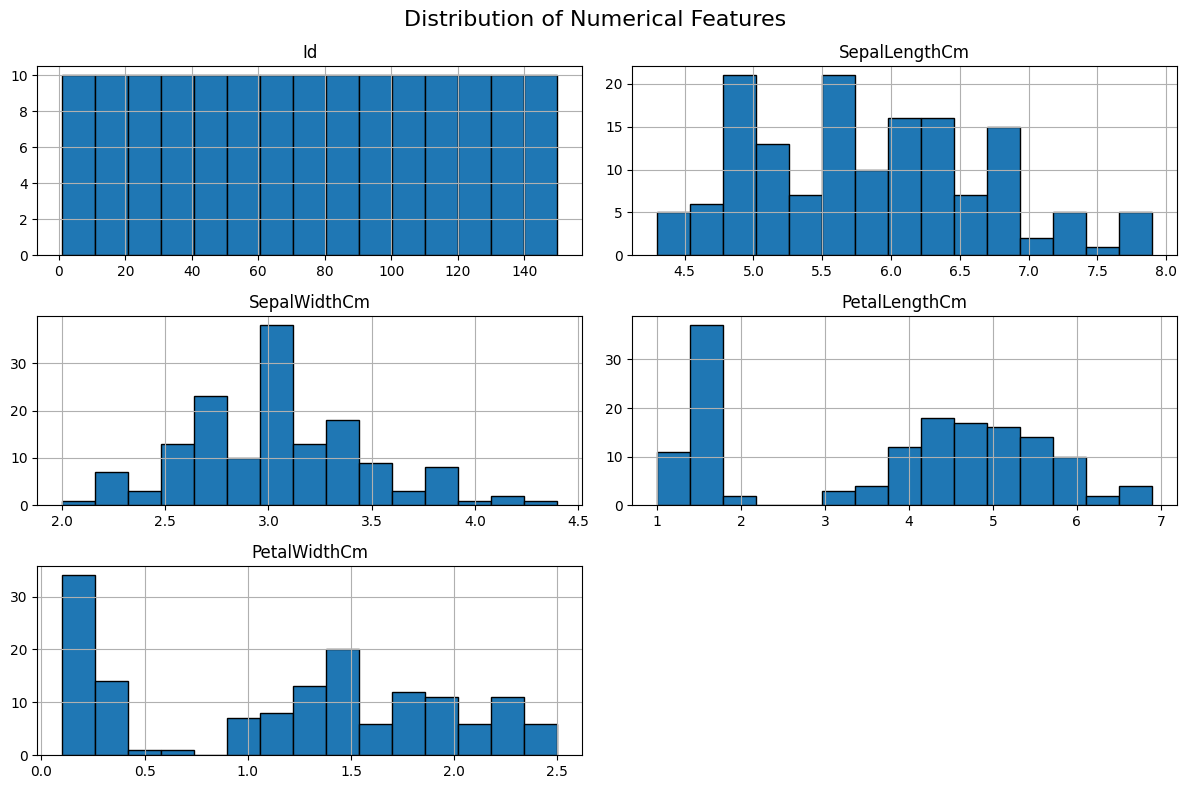

In [11]:
# visualize
import matplotlib.pyplot as plt

# Select all numerical columns
numeric_df = df.select_dtypes(include="number")

# Draw a histogram for each numerical column
numeric_df.hist(figsize=(12, 8), bins=15, edgecolor="black")

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [12]:

# Select the four flower measurements as input features
X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

# Select the species as the target
y = df["Species"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature shape: (150, 4)
Target shape: (150,)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,Species
0,Iris-setosa
1,Iris-setosa
2,Iris-setosa
3,Iris-setosa
4,Iris-setosa


In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)

Training class distribution:
Species
Iris-setosa        40
Iris-virginica     40
Iris-versicolor    40
Name: count, dtype: int64

Testing class distribution:
Species
Iris-setosa        10
Iris-virginica     10
Iris-versicolor    10
Name: count, dtype: int64


#Step 4 — Train your first Random Forest model

In [14]:

from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model using the training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


Make prediction after learning

In [15]:

# Predict species for the test data
y_pred = model.predict(X_test)

# Compare actual and predicted species
results = X_test.copy()
results["Actual Species"] = y_test
results["Predicted Species"] = y_pred

display(results.head(10))

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Actual Species,Predicted Species
38,4.4,3.0,1.3,0.2,Iris-setosa,Iris-setosa
127,6.1,3.0,4.9,1.8,Iris-virginica,Iris-virginica
57,4.9,2.4,3.3,1.0,Iris-versicolor,Iris-versicolor
93,5.0,2.3,3.3,1.0,Iris-versicolor,Iris-versicolor
42,4.4,3.2,1.3,0.2,Iris-setosa,Iris-setosa
56,6.3,3.3,4.7,1.6,Iris-versicolor,Iris-versicolor
22,4.6,3.6,1.0,0.2,Iris-setosa,Iris-setosa
20,5.4,3.4,1.7,0.2,Iris-setosa,Iris-setosa
147,6.5,3.0,5.2,2.0,Iris-virginica,Iris-virginica
84,5.4,3.0,4.5,1.5,Iris-versicolor,Iris-versicolor


# Step 5 — Evaluate model performance

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy Percentage: {accuracy * 100:.2f}%")

# Calculate precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

Test Accuracy: 0.9000
Test Accuracy Percentage: 90.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa     1.0000    1.0000    1.0000        10
Iris-versicolor     0.8182    0.9000    0.8571        10
 Iris-virginica     0.8889    0.8000    0.8421        10

       accuracy                         0.9000        30
      macro avg     0.9024    0.9000    0.8997        30
   weighted avg     0.9024    0.9000    0.8997        30



Confusion matrix

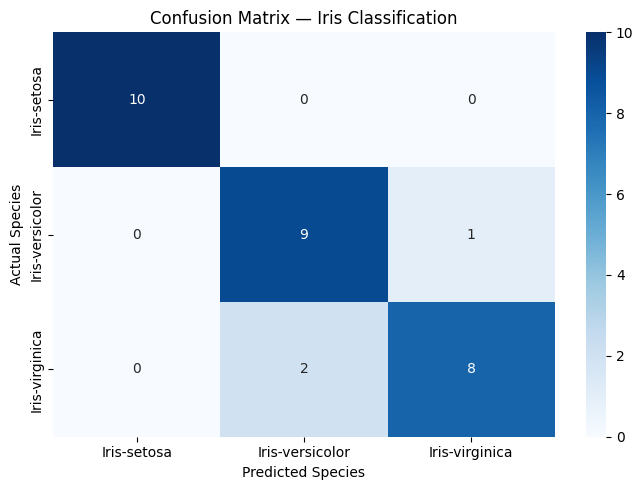

In [17]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

# Visualize it
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix — Iris Classification")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

,Feature,Importance
3,PetalWidthCm,0.437185
2,PetalLengthCm,0.431466
0,SepalLengthCm,0.116349
1,SepalWidthCm,0.015000


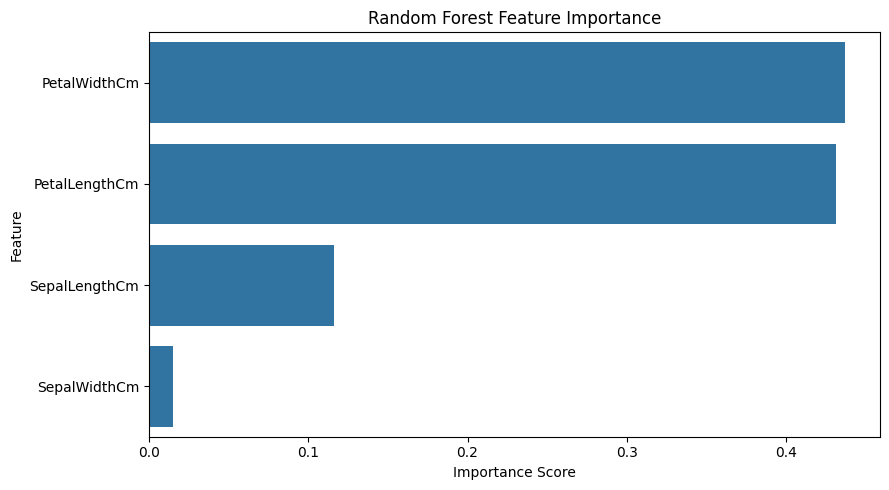

In [18]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the importance score for each feature
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Sort features from most to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Step 6 — Compare models

In [19]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, clf in models.items():
    # Train the current model
    clf.fit(X_train, y_train)

    # Predict the test labels
    predictions = clf.predict(X_test)

    # Store evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-score (Macro)",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
1,SVM,0.9667,0.9697,0.9667,0.9666
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
2,Decision Tree,0.9333,0.9333,0.9333,0.9333
3,Random Forest,0.9000,0.9024,0.9000,0.8997


Support Vector Machine (SVM) performed better here